In [1]:
import pandas as pd
import numpy as np

In [2]:
train_df = pd.read_csv('data/train.csv')
test_df = pd.read_csv('data/test.csv')

x_train, y_train = train_df['msg'], train_df['label']
x_test, y_test = test_df['msg'], test_df['label']

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV

pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])

param_grid = {
    'model__C': [0.1, 0.5, 1, 5, 10, 50, 100],
    'model__class_weight': ['balanced', None]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(x_train, y_train)

print('Best parameters:', grid_search.best_params_)
print('Best CV F1 (macro):', grid_search.best_score_)

Fitting 5 folds for each of 14 candidates, totalling 70 fits
Best parameters: {'model__C': 100, 'model__class_weight': None}
Best CV F1 (macro): 0.9455997905318723


In [4]:
cv_results = pd.DataFrame(grid_search.cv_results_)
cv_results[['param_model__C', 'param_model__class_weight',
            'mean_test_score', 'std_test_score', 'rank_test_score']].sort_values('rank_test_score').head(10)

,param_model__C,param_model__class_weight,mean_test_score,std_test_score,rank_test_score
13,100.0,NaN,0.945600,0.007401,1
10,50.0,balanced,0.944919,0.010391,2
12,100.0,balanced,0.944919,0.010391,2
8,10.0,balanced,0.944645,0.011222,4
11,50.0,NaN,0.941564,0.007248,5
6,5.0,balanced,0.941442,0.012223,6
9,10.0,NaN,0.934289,0.011647,7
4,1.0,balanced,0.929109,0.017518,8
2,0.5,balanced,0.923910,0.015597,9
7,5.0,NaN,0.919971,0.014096,10


In [5]:
best_model = grid_search.best_estimator_
vocab_size = len(best_model.named_steps['tfidf'].vocabulary_)
print('Vocabulary size (TF-IDF features):', vocab_size)

Vocabulary size (TF-IDF features): 6800


In [6]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred = best_model.predict(x_test)

print(f'Accuracy: {accuracy_score(y_test, y_pred):.4f}')
print('Classification report:')
print(classification_report(y_test, y_pred))
print('Confusion matrix:')
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9717
Classification report:
              precision    recall  f1-score   support

         ham       0.98      0.99      0.98      1344
        spam       0.94      0.81      0.87       175

    accuracy                           0.97      1519
   macro avg       0.96      0.90      0.93      1519
weighted avg       0.97      0.97      0.97      1519

Confusion matrix:
[[1335    9]
 [  34  141]]


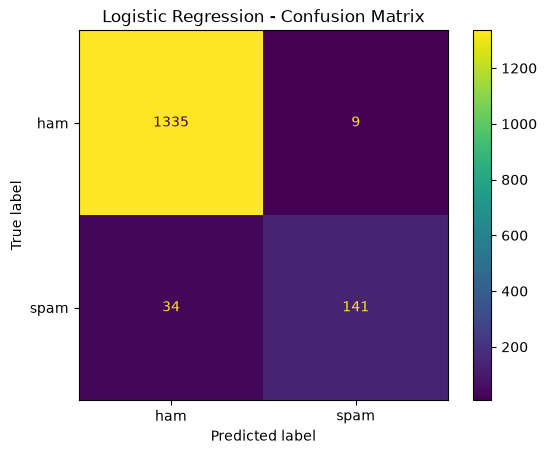

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test,y_pred)

plt.title("Logistic Regression - Confusion Matrix")

plt.show()

In [8]:
import joblib
joblib.dump(best_model, '../models/logistic_regression_text.pkl')

['../models/logistic_regression_text.pkl']